In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
ds = pd.read_csv(r"C:\Users\chinm\Desktop\ml\Rock vs Mine Prediction\Copy of sonar data.csv", header=None)

In [3]:
ds.head(5)

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [4]:
ds.shape


(208, 61)

In [5]:
ds.describe()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900


In [6]:
ds[60].value_counts()

60
M    111
R     97
Name: count, dtype: int64

In [7]:
ds.groupby(60).mean()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
60,,,,,,,,,,,,,,,,,,,,,
M,0.034989,0.045544,0.050720,0.064768,0.086715,0.111864,0.128359,0.149832,0.213492,0.251022,...,0.019352,0.016014,0.011643,0.012185,0.009923,0.008914,0.007825,0.009060,0.008695,0.006930
R,0.022498,0.030303,0.035951,0.041447,0.062028,0.096224,0.114180,0.117596,0.137392,0.159325,...,0.012311,0.010453,0.009640,0.009518,0.008567,0.007430,0.007814,0.006677,0.007078,0.006024


Train Test Split

In [8]:
X = ds.drop(columns=60, axis=1)
Y = ds[60]

In [9]:
x_train,x_test, y_train, y_test = train_test_split(X,Y, test_size= 0.2, stratify=Y, random_state=25)

In [10]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)


(166, 60) (42, 60) (166,) (42,)


Model Training


In [11]:
model = LogisticRegression()

In [12]:
model.fit(x_train, y_train)

LogisticRegression()

In [13]:
#Training score
prd = model.predict(x_train)
train_score = accuracy_score(prd, y_train)
print(train_score)

0.8554216867469879


In [14]:
#Testing score
prd_1 = model.predict(x_test)
test_score = accuracy_score(prd_1, y_test)
print(test_score)

0.7380952380952381


In [15]:
y_pred_lr = model.predict(x_test)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           M       0.70      0.86      0.78        22
           R       0.80      0.60      0.69        20

    accuracy                           0.74        42
   macro avg       0.75      0.73      0.73        42
weighted avg       0.75      0.74      0.73        42



In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

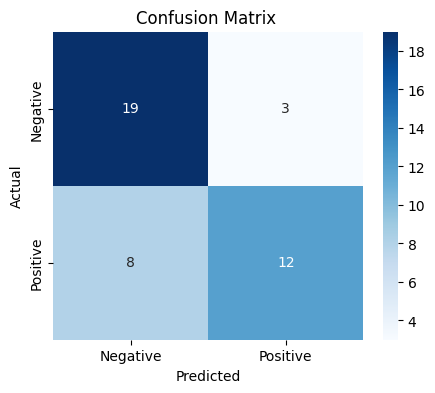

In [18]:
cm = confusion_matrix(y_test, y_pred_lr)


plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix ")
plt.show()

Making a Predictive System

In [19]:
input_data = (0.0261,0.0266,0.0223,0.0749,0.1364,0.1513,0.1316,0.1654,0.1864,0.2013,0.2890,0.3650,0.3510,0.3495,0.4325,0.5398,0.6237,0.6876,0.7329,0.8107,0.8396,0.8632,0.8747,0.9607,0.9716,0.9121,0.8576,0.8798,0.7720,0.5711,0.4264,0.2860,0.3114,0.2066,0.1165,0.0185,0.1302,0.2480,0.1637,0.1103,0.2144,0.2033,0.1887,0.1370,0.1376,0.0307,0.0373,0.0606,0.0399,0.0169,0.0135,0.0222,0.0175,0.0127,0.0022,0.0124,0.0054,0.0021,0.0028,0.0023)
input_data_as_ary = np.array(input_data)

# reshape the np array as we are predicting for one instance
reshape = input_data_as_ary.reshape(1,-1)

prediction = model.predict(reshape)
# print(prediction)

if(prediction == 'R'):
    print("It is a Rock")

else:
    print("It is a Mine")

It is a Mine
